### GitHub Link: https://github.com/gomiiie/BloodCells_CNN

# Imports + GPU Set

In [1]:
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import random_split, Dataset, DataLoader
import torch
import torch.nn as nn
import numpy as np

import os
from PIL import Image
import matplotlib.pyplot as plt

from torchsummary import summary

import kagglehub

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


# Data Loading

In [2]:
path = kagglehub.dataset_download("unclesamulus/blood-cells-image-dataset") #dl from kaggle
path = os.path.join(path, "bloodcells_dataset") #folder name join
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset


In [3]:
#hyperparameters
size = 256 
batch_size = 32
learning_rate = 1e-3
epoch_number = 10

### Image Preview

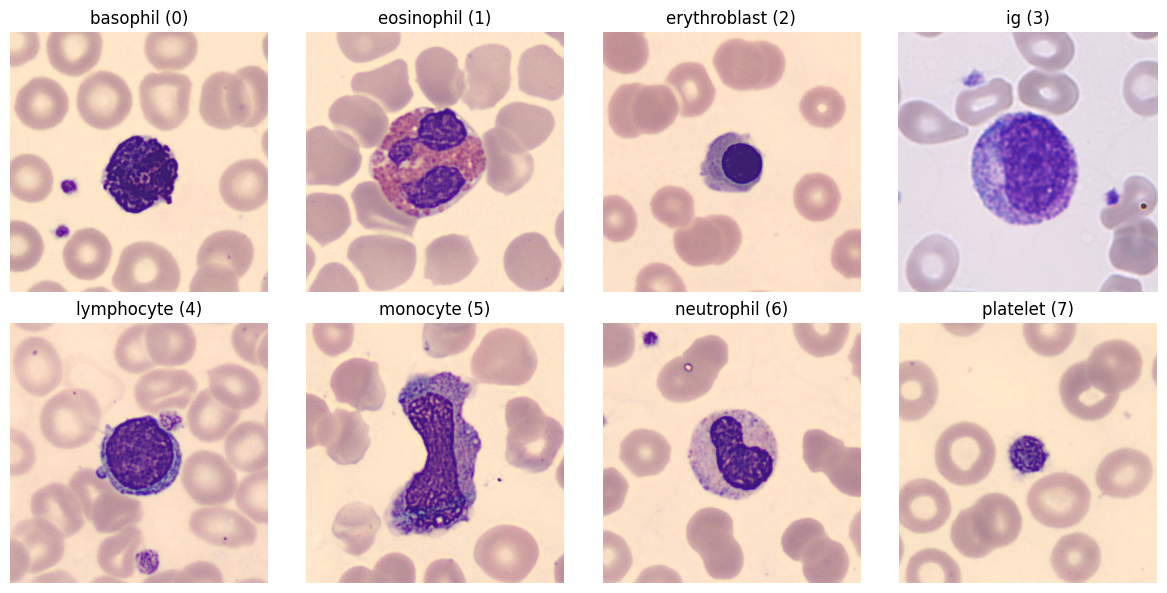

In [4]:
classes = sorted(os.listdir(path)) #gets all folder names
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    #gets path to 1 image for each class
    folder = os.path.join(path, classes[i])
    first_img = os.listdir(folder)[0]
    img_path = os.path.join(os.path.join(folder, first_img))

    #plots image
    ax.imshow(Image.open(img_path))
    ax.set_title(f"{classes[i]} ({i})")
    ax.axis('off')

plt.tight_layout()
plt.show()

# Preprocessing & Augmentation + Split

In [5]:
#train set augmentation so that it doesn't memorize, + preprocessing (resize, and normalize) 
train_transform = transforms.Compose([
    transforms.Resize((size, size)),      
    transforms.RandomHorizontalFlip(),   
    transforms.RandomRotation(15),       
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor() 
])

#valtest set preprocessing 
val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

#load dataset twice using imagefolder for easy splitting later
all_data = datasets.ImageFolder(path, transform=train_transform)
testval_data = datasets.ImageFolder(path, transform=val_transform)

print(f"Classes ({len(all_data.classes)}):{all_data.classes} ")
print("Total images:", len(all_data))

Classes (8):['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet'] 
Total images: 17092


In [6]:
#calculate set size for 80-10-10 split
train_size = int(0.8 * len(all_data))
val_size   = int(0.1 * len(all_data))
test_size  = len(all_data) - train_size - val_size

#split train with seed
train_data, _, _ = random_split(
    all_data,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

#split test with seed
_, val_data, test_data = random_split(
    testval_data,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)   

In [7]:
#create dataloader with data in batches
trn_dl  = DataLoader(train_data, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
val_dl  = DataLoader(val_data, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_data, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

print("Image shape:", train_data[0][0].shape)
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))

Image shape: torch.Size([3, 256, 256])
Train Data:  13673
Validation Data:  1709
Test Data:  1710


# CNN Architecutre

In [8]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        #layer 1
        nn.Conv2d(3, 32, kernel_size=3, padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #layer 2
        nn.Conv2d(32, 64, kernel_size=3, padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #layer 3
        nn.Conv2d(64, 128, kernel_size=3, padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #layer 4
        nn.Conv2d(128, 256, kernel_size=3, padding = 1),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(256*16*16, 128),
        nn.ReLU(),
        nn.Linear(128, 8)
    ).to(device)
    #32, 64,  128,  256; lots of layers to pick up more tiny features in cell nucleus
    #padding for edge details
    #256*16*16 -> 128 more refined features and not as dense linear part
    #final classification head with 8 classes

    
    #loss function, CEL since multi class
    #adam for fast convergence and lesser iterations
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,256,256)); #model parameters details

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 256, 256]             896
              ReLU-2         [-1, 32, 256, 256]               0
         MaxPool2d-3         [-1, 32, 128, 128]               0
            Conv2d-4         [-1, 64, 128, 128]          18,496
              ReLU-5         [-1, 64, 128, 128]               0
         MaxPool2d-6           [-1, 64, 64, 64]               0
            Conv2d-7          [-1, 128, 64, 64]          73,856
              ReLU-8          [-1, 128, 64, 64]               0
         MaxPool2d-9          [-1, 128, 32, 32]               0
           Conv2d-10          [-1, 256, 32, 32]         295,168
             ReLU-11          [-1, 256, 32, 32]               0
        MaxPool2d-12          [-1, 256, 16, 16]               0
          Flatten-13                [-1, 65536]               0
           Linear-14                  [

# Training

In [9]:
#train val code copy pasted, for one epoch and for validating per epoch
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device) 
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [10]:
#copy pasted from example, iterating epoch_number times, running trainoneepoch and validation  
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 1.3288 | Train Accuracy: 47.54% | Val Loss: 0.8255 | Val Accuracy: 66.47%
Epoch [2/10] | Train Loss: 0.6788 | Train Accuracy: 73.98% | Val Loss: 0.4712 | Val Accuracy: 84.61%
Epoch [3/10] | Train Loss: 0.4689 | Train Accuracy: 82.90% | Val Loss: 0.3835 | Val Accuracy: 85.43%
Epoch [4/10] | Train Loss: 0.3603 | Train Accuracy: 87.54% | Val Loss: 0.2862 | Val Accuracy: 90.05%
Epoch [5/10] | Train Loss: 0.2911 | Train Accuracy: 89.82% | Val Loss: 0.2559 | Val Accuracy: 91.81%
Epoch [6/10] | Train Loss: 0.2259 | Train Accuracy: 92.12% | Val Loss: 0.1912 | Val Accuracy: 94.21%
Epoch [7/10] | Train Loss: 0.2118 | Train Accuracy: 92.83% | Val Loss: 0.2046 | Val Accuracy: 92.98%
Epoch [8/10] | Train Loss: 0.2002 | Train Accuracy: 93.27% | Val Loss: 0.1709 | Val Accuracy: 94.73%
Epoch [9/10] | Train Loss: 0.1739 | Train Accuracy: 93.94% | Val Loss: 0.1804 | Val Accuracy: 94.50%
Epoch [10/10] | Train Loss: 0.1532 | Train Accuracy: 94.91% | Val Loss: 0.1375 | Val Accura

# Visualizations

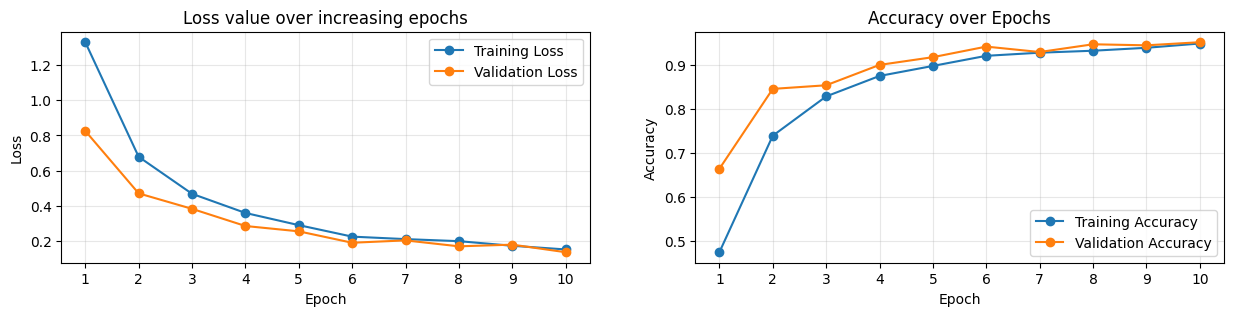

In [11]:
#training and val acc, training and val loss
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Test Evaluation and Model Saving

In [12]:
#runs val function on test set instead
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.13 , Test Accuracy: 96.08%


In [13]:
#for one example
@torch.no_grad()
def predictOne(model, img, classes=None):
    model.eval()
    img_in = img.view(-1, 3, size, size).to(device)
    np_output = model(img_in).cpu().detach().numpy()
    pred = np.exp(np_output) / np.sum(np.exp(np_output))
    
    plt.figure(figsize=(2, 2))
    plt.imshow(img.permute(1, 2, 0))
    plt.title(f"{classes[pred.argmax()]} ({pred.max()*100:.2f}%)" if classes is not None else pred.argmax())
    plt.axis('off')
    plt.show()

In [14]:
#saves model
torch.save(model.state_dict(), 'model.pth')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 256, 256]             896
              ReLU-2         [-1, 32, 256, 256]               0
         MaxPool2d-3         [-1, 32, 128, 128]               0
            Conv2d-4         [-1, 64, 128, 128]          18,496
              ReLU-5         [-1, 64, 128, 128]               0
         MaxPool2d-6           [-1, 64, 64, 64]               0
            Conv2d-7          [-1, 128, 64, 64]          73,856
              ReLU-8          [-1, 128, 64, 64]               0
         MaxPool2d-9          [-1, 128, 32, 32]               0
           Conv2d-10          [-1, 256, 32, 32]         295,168
             ReLU-11          [-1, 256, 32, 32]               0
        MaxPool2d-12          [-1, 256, 16, 16]               0
          Flatten-13                [-1, 65536]               0
           Linear-14                  [

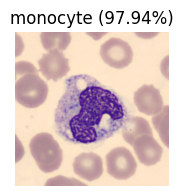

In [15]:
#uses saved model to test one test image
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth'))
saved_model.eval()
summary(saved_model, (3, size, size))

img, label = test_data[np.random.randint(0, len(test_data))]
predictOne(saved_model, img, all_data.classes)